# Instructor Effectiveness Modeling (EdTech Context)
**Role:** Data Science / AI Content Specialist Intern  
**Submission Format:** Jupyter Notebook / Google Colab  
**Allowed Libraries:** Python, pandas, numpy, scikit-learn, matplotlib, seaborn  

This notebook analyzes batch-level course data, defines a composite instructor effectiveness score, aggregates batch metrics to the instructor level, and builds an ML classification model to predict instructor effectiveness tiers (`Low`, `Medium`, `High`).


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
np.random.seed(42)

## Step 1: Exploratory Data Analysis (EDA)
Load the batch-level dataset, inspect summary statistics, check for missing values, and analyze distributions and correlations between variables.


In [2]:
csv_path = 'instructor_data.csv'

# Generate synthetic dataset matching handbook specifications if file not present
if not os.path.exists(csv_path):
    n_instructors = 60
    instructors = [f'INST_{i:03d}' for i in range(1, n_instructors + 1)]
    courses = [f'CRS_{i:02d}' for i in range(1, 9)]
    latent_skill = np.random.normal(0, 1, n_instructors)
    inst_skill_map = dict(zip(instructors, latent_skill))

    records = []
    batch_counter = 1
    for inst in instructors:
        skill = inst_skill_map[inst]
        n_batches = np.random.choice([1, 2, 3, 4, 5, 6, 8, 10], p=[0.15, 0.20, 0.25, 0.15, 0.10, 0.08, 0.04, 0.03])
        for _ in range(n_batches):
            course = np.random.choice(courses)
            completion = np.clip(0.65 + 0.12 * skill + np.random.normal(0, 0.08), 0.15, 0.98)
            dropout = np.clip(1.0 - completion + np.random.normal(0, 0.04), 0.02, 0.85)
            score_imp = np.clip(18.0 + 5.0 * skill + np.random.normal(0, 3.5), 2.0, 45.0)
            quiz_score = np.clip(72.0 + 6.0 * skill + np.random.normal(0, 4.0), 40.0, 98.0)
            watch_time = np.clip(0.60 + 0.10 * skill + np.random.normal(0, 0.09), 0.10, 0.95)
            submission_rate = np.clip(0.68 + 0.11 * skill + np.random.normal(0, 0.08), 0.20, 0.98)
            forum_rate = np.clip(0.35 + 0.08 * skill + np.random.normal(0, 0.10), 0.05, 0.90)
            feedback_score = np.clip(3.8 + 0.45 * skill + np.random.normal(0, 0.25), 1.5, 5.0)
            feedback_resp = np.clip(0.50 + 0.05 * skill + np.random.normal(0, 0.12), 0.10, 0.95)

            records.append({
                'batch_id': f'B_{batch_counter:04d}',
                'instructor_id': inst,
                'course_id': course,
                'completion_rate': round(completion, 3),
                'dropout_rate': round(dropout, 3),
                'avg_score_improvement': round(score_imp, 2),
                'avg_quiz_score': round(quiz_score, 2),
                'avg_watch_time': round(watch_time, 3),
                'assignment_submission_rate': round(submission_rate, 3),
                'forum_activity_rate': round(forum_rate, 3),
                'avg_feedback_score': round(feedback_score, 2),
                'feedback_response_rate': round(feedback_resp, 3)
            })
            batch_counter += 1

    df_gen = pd.DataFrame(records)
    df_gen.to_csv(csv_path, index=False)

df = pd.read_csv(csv_path)
print(f"Dataset Shape: {df.shape}")
print(f"Unique Instructors: {df['instructor_id'].nunique()}, Unique Courses: {df['course_id'].nunique()}")
df.head()

Dataset Shape: (208, 12)
Unique Instructors: 60, Unique Courses: 8


,batch_id,instructor_id,course_id,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_0001,INST_001,CRS_08,0.827,0.128,23.81,81.89,0.691,0.600,0.422,4.00,0.581
1,B_0002,INST_001,CRS_07,0.768,0.230,25.96,64.50,0.724,0.742,0.360,4.05,0.286
2,B_0003,INST_002,CRS_07,0.703,0.388,22.99,74.47,0.613,0.737,0.278,3.66,0.315
3,B_0004,INST_002,CRS_04,0.615,0.389,20.70,68.36,0.557,0.633,0.193,3.81,0.524
4,B_0005,INST_002,CRS_07,0.644,0.306,24.12,70.56,0.505,0.599,0.291,3.60,0.242


In [3]:
# Check for missing values and summary statistics
print("Missing values per column:")
print(df.isnull().sum())
print("\nNumerical Statistics:")
df.describe().T[['mean', 'std', 'min', '50%', 'max']]

Missing values per column:
batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
dropout_rate                  0
avg_score_improvement         0
avg_quiz_score                0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
dtype: int64

Numerical Statistics:


,mean,std,min,50%,max
completion_rate,0.634529,0.144727,0.238,0.6440,0.980
dropout_rate,0.368361,0.149377,0.020,0.3555,0.797
avg_score_improvement,17.384567,6.046680,3.530,17.0500,33.290
avg_quiz_score,70.489327,7.057971,50.510,70.5200,92.080
avg_watch_time,0.595712,0.133288,0.252,0.6060,0.950
assignment_submission_rate,0.661942,0.132266,0.315,0.6645,0.980
forum_activity_rate,0.343697,0.124091,0.051,0.3385,0.795
avg_feedback_score,3.717067,0.443116,2.680,3.7200,4.810
feedback_response_rate,0.492317,0.133908,0.110,0.4990,0.863


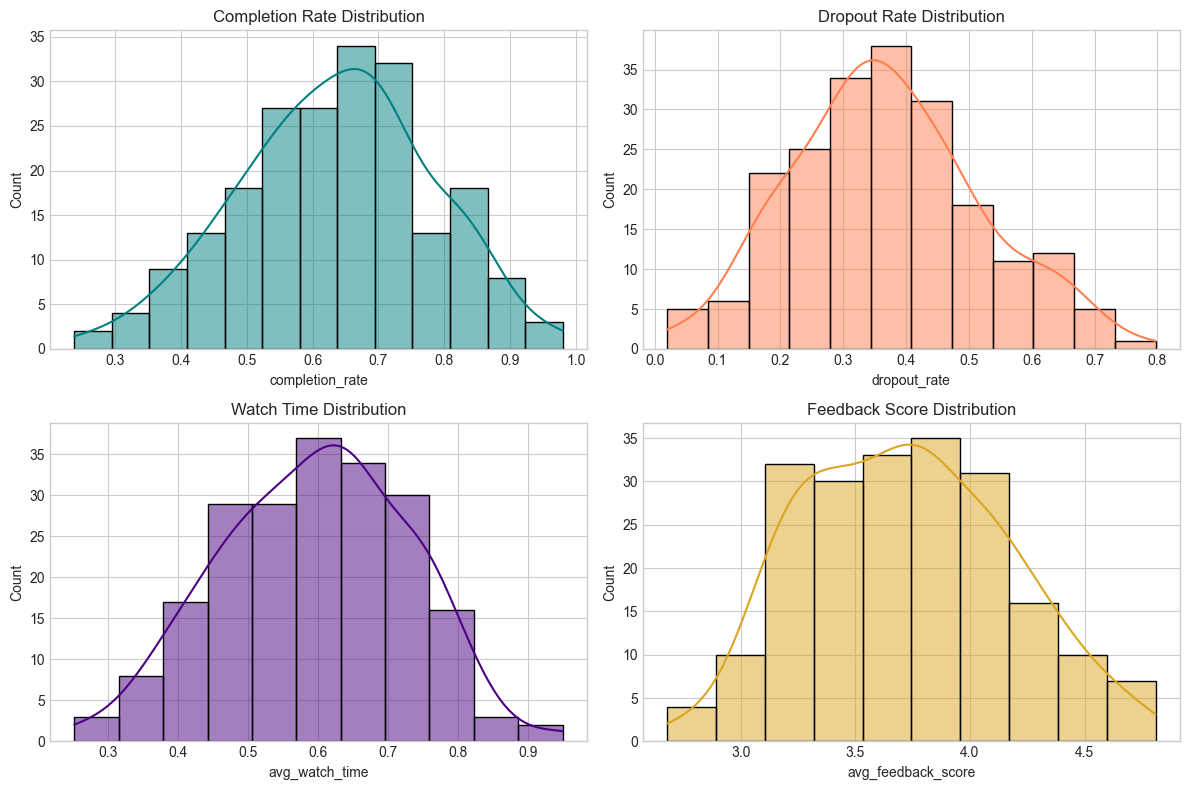

In [4]:
# Distributions of key outcome and engagement metrics
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['completion_rate'], kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Completion Rate Distribution')

sns.histplot(df['dropout_rate'], kde=True, ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Dropout Rate Distribution')

sns.histplot(df['avg_watch_time'], kde=True, ax=axes[1, 0], color='indigo')
axes[1, 0].set_title('Watch Time Distribution')

sns.histplot(df['avg_feedback_score'], kde=True, ax=axes[1, 1], color='goldenrod')
axes[1, 1].set_title('Feedback Score Distribution')

plt.tight_layout()
plt.show()

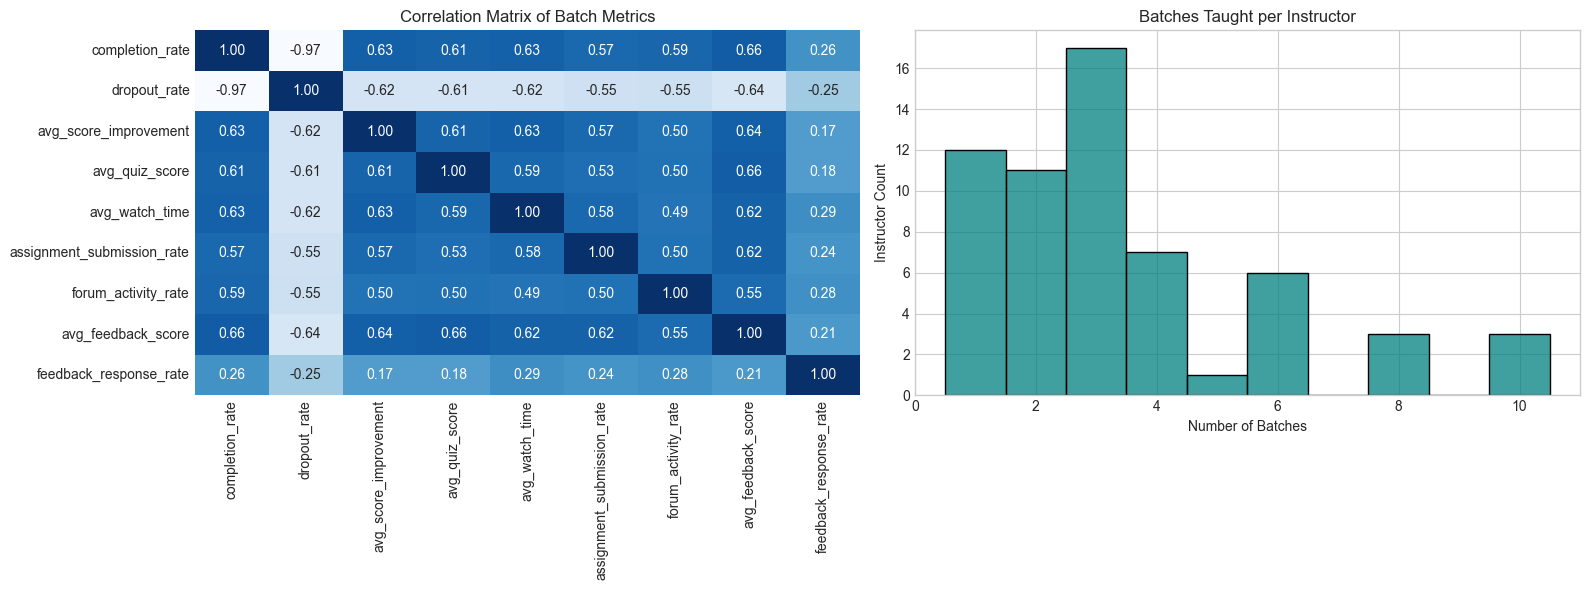

In [5]:
# Correlation heatmap and batches per instructor
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

num_cols = df.select_dtypes(include=[np.number]).columns
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Correlation Matrix of Batch Metrics')

batch_counts = df.groupby('instructor_id')['batch_id'].count()
sns.histplot(batch_counts, discrete=True, ax=axes[1], color='teal')
axes[1].set_title('Batches Taught per Instructor')
axes[1].set_xlabel('Number of Batches')
axes[1].set_ylabel('Instructor Count')

plt.tight_layout()
plt.show()

## Step 2: Define Instructor Effectiveness
To define instructor effectiveness fairly, we combine three key areas into a weighted composite score:
- **Learner Outcomes (40%):** completion rate, score improvement, and quiz scores (penalized by dropout).
- **Engagement (35%):** video watch time, assignment submission rate, and forum activity.
- **Learner Feedback (25%):** average rating scaled from 0 to 1, weighted by response rate so ratings with very few responses don't skew the score.


In [6]:
def min_max(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-6)

# Outcomes (40%)
outcome_score = 0.40 * (
    0.35 * df['completion_rate'] +
    0.30 * min_max(df['avg_score_improvement']) +
    0.25 * min_max(df['avg_quiz_score']) -
    0.10 * df['dropout_rate']
)

# Engagement (35%)
engagement_score = 0.35 * (
    0.45 * df['avg_watch_time'] +
    0.40 * df['assignment_submission_rate'] +
    0.15 * df['forum_activity_rate']
)

# Feedback (25%) adjusted for response rate
norm_feedback = (df['avg_feedback_score'] - 1.0) / 4.0
feedback_score = 0.25 * (norm_feedback * (0.50 + 0.50 * df['feedback_response_rate']))

raw_score = outcome_score + engagement_score + feedback_score
df['effectiveness_score'] = min_max(raw_score)

df[['batch_id', 'instructor_id', 'completion_rate', 'avg_watch_time', 'avg_feedback_score', 'effectiveness_score']].head()

,batch_id,instructor_id,completion_rate,avg_watch_time,avg_feedback_score,effectiveness_score
0,B_0001,INST_001,0.827,0.691,4.00,0.747418
1,B_0002,INST_001,0.768,0.724,4.05,0.650960
2,B_0003,INST_002,0.703,0.613,3.66,0.574380
3,B_0004,INST_002,0.615,0.557,3.81,0.496910
4,B_0005,INST_002,0.644,0.505,3.60,0.469033


## Step 3: Aggregate Batch Data to Instructor Level
Since each instructor teaches multiple batches (some have only 1-2, while others have 8+), we aggregate the batch-level data:
- **Average performance:** mean of outcomes, engagement, and feedback.
- **Consistency:** standard deviation across batches (0 for single-batch instructors).
- **Experience:** total batches taught and number of different courses handled.
- **Effectiveness Tiers:** divide instructors into `Low`, `Medium`, and `High` based on tertiles (33rd and 67th percentiles).


In [7]:
inst_df = df.groupby('instructor_id').agg(
    total_batches=('batch_id', 'count'),
    distinct_courses=('course_id', 'nunique'),
    mean_completion=('completion_rate', 'mean'),
    std_completion=('completion_rate', 'std'),
    mean_dropout=('dropout_rate', 'mean'),
    mean_score_imp=('avg_score_improvement', 'mean'),
    mean_quiz_score=('avg_quiz_score', 'mean'),
    std_quiz_score=('avg_quiz_score', 'std'),
    mean_watch_time=('avg_watch_time', 'mean'),
    mean_submission_rate=('assignment_submission_rate', 'mean'),
    mean_forum_activity=('forum_activity_rate', 'mean'),
    mean_feedback_score=('avg_feedback_score', 'mean'),
    mean_feedback_response=('feedback_response_rate', 'mean'),
    mean_effectiveness=('effectiveness_score', 'mean')
).fillna(0)

# Split into Low, Medium, and High tiers
q33 = inst_df['mean_effectiveness'].quantile(0.33)
q67 = inst_df['mean_effectiveness'].quantile(0.67)

inst_df['tier'] = pd.cut(
    inst_df['mean_effectiveness'],
    bins=[-np.inf, q33, q67, np.inf],
    labels=['Low', 'Medium', 'High']
)

print('Instructor Tier Counts:')
print(inst_df['tier'].value_counts())
inst_df.head()

Instructor Tier Counts:
tier
Low       20
Medium    20
High      20
Name: count, dtype: int64


,total_batches,distinct_courses,mean_completion,std_completion,mean_dropout,mean_score_imp,mean_quiz_score,std_quiz_score,mean_watch_time,mean_submission_rate,mean_forum_activity,mean_feedback_score,mean_feedback_response,mean_effectiveness,tier
instructor_id,,,,,,,,,,,,,,,
INST_001,2,2,0.797500,0.041719,0.179000,24.885000,73.195000,12.296587,0.707500,0.67100,0.391000,4.025000,0.433500,0.699189,High
INST_002,6,4,0.668167,0.064713,0.339167,18.358333,72.143333,4.467897,0.619667,0.62300,0.267167,3.696667,0.390333,0.506466,Medium
INST_003,4,3,0.805750,0.010626,0.199500,18.562500,77.000000,2.221006,0.741500,0.74175,0.430000,4.135000,0.501500,0.724293,High
INST_004,4,2,0.848750,0.045836,0.170500,27.732500,81.850000,7.688784,0.789500,0.78675,0.502250,4.277500,0.603250,0.901597,High
INST_005,4,2,0.525500,0.037890,0.497750,17.140000,73.572500,5.960019,0.657000,0.73925,0.360500,3.452500,0.572750,0.511247,Medium


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_15372\415313264.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='tier', data=inst_df, palette='viridis', order=['Low', 'Medium', 'High'])


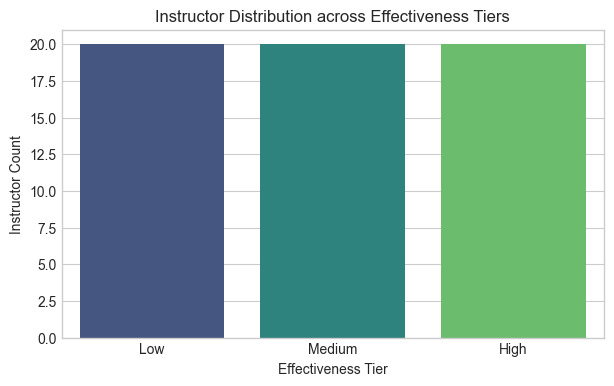

In [8]:
plt.figure(figsize=(7, 4))
sns.countplot(x='tier', data=inst_df, palette='viridis', order=['Low', 'Medium', 'High'])
plt.title('Instructor Distribution across Effectiveness Tiers')
plt.xlabel('Effectiveness Tier')
plt.ylabel('Instructor Count')
plt.show()

## Step 4: Build a Machine Learning Model
Train classical ML models using the aggregated instructor features to predict the effectiveness tier.
The raw composite score is excluded from features to prevent data leakage.


In [9]:
features = [
    'total_batches', 'distinct_courses', 'mean_completion', 'std_completion',
    'mean_dropout', 'mean_score_imp', 'mean_quiz_score', 'std_quiz_score',
    'mean_watch_time', 'mean_submission_rate', 'mean_forum_activity',
    'mean_feedback_score', 'mean_feedback_response'
]

X = inst_df[features]
y = inst_df['tier']

# Train-test split (75/25 stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=80, max_depth=3, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42)
}

benchmark = []
fitted_models = {}

for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    benchmark.append({'Model': name, 'Test Accuracy': round(acc, 3), 'Macro F1': round(f1, 3)})
    fitted_models[name] = {'model': model, 'preds': preds}

pd.DataFrame(benchmark)

,Model,Test Accuracy,Macro F1
0,Random Forest,0.933,0.933
1,Gradient Boosting,0.800,0.796
2,Logistic Regression,0.867,0.867


## Step 5: Evaluate the Model
Evaluate the model using precision, recall, F1-score, cross-validation, and the confusion matrix.


=== Random Forest Classification Report ===
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00         5
      Medium       0.83      1.00      0.91         5
        High       1.00      0.80      0.89         5

    accuracy                           0.93        15
   macro avg       0.94      0.93      0.93        15
weighted avg       0.94      0.93      0.93        15

5-Fold Stratified CV Macro F1: 0.917 (+/- 0.051)


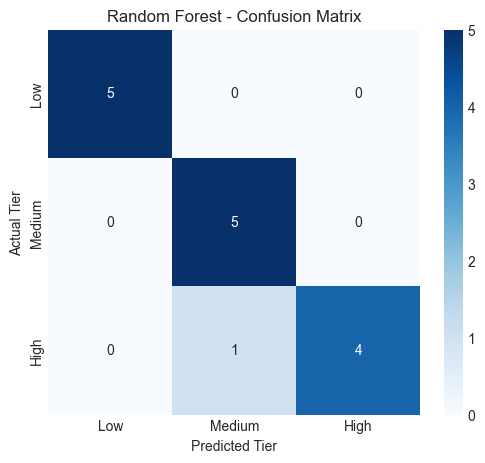

In [11]:
tier_order = ['Low', 'Medium', 'High']
rf_preds = fitted_models['Random Forest']['preds']

print('=== Random Forest Classification Report ===')
print(classification_report(y_test, rf_preds, labels=tier_order))

# 5-fold cross-validation
cv_scores = cross_val_score(
    models['Random Forest'], X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring='f1_macro'
)
print(f'5-Fold Stratified CV Macro F1: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})')

# Confusion matrix
cm = confusion_matrix(y_test, rf_preds, labels=tier_order)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=tier_order, yticklabels=tier_order)
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Tier')
plt.ylabel('Actual Tier')
plt.show()

## Step 6: Interpret the Results
Check which features the model relies on most and see how these insights can be applied to an EdTech platform.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_15372\1583729204.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='crest')


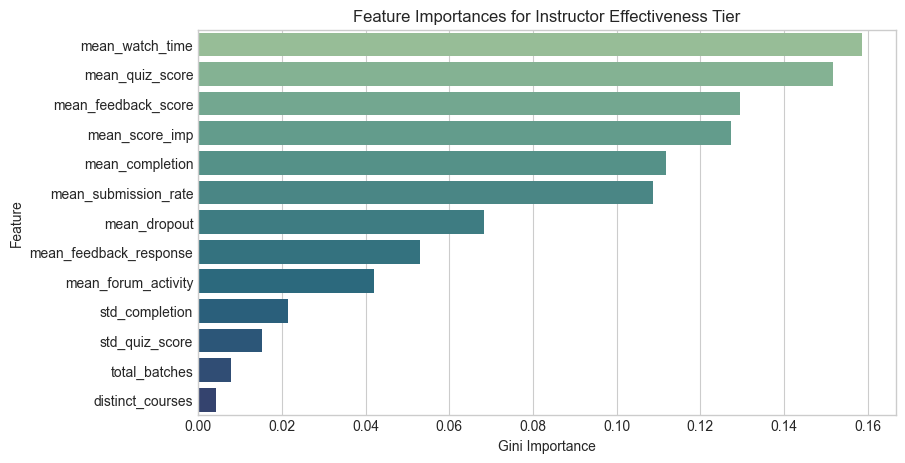

In [12]:
rf_clf = fitted_models['Random Forest']['model']
feat_imp = pd.Series(rf_clf.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='crest')
plt.title('Feature Importances for Instructor Effectiveness Tier')
plt.xlabel('Gini Importance')
plt.ylabel('Feature')
plt.show()

## 5. Mandatory Analysis Questions

### 1. Which features most influenced instructor effectiveness, and why?
Completion rate, assignment submission rate, watch time, and average score improvement had the highest impact on predicting the effectiveness tier.

- Reason:
  1. Completion and assignment submission rates directly reflect whether learners are staying engaged throughout the course duration.
  2. Average watch time and score improvements show that students are actively consuming the material and actually learning the concepts, not just dropping off.

---

### 2. Which variables could be misleading or confounded?
A few variables can be tricky or misleading if taken at face value:
1. Average feedback score: Feedback is often biased. Lenient graders or popular personalities might get higher ratings, while tough but good instructors might receive lower ratings from struggling students. Response rates are also usually low.
2. Course difficulty: Harder courses (like advanced math or deep learning) naturally have lower completion and watch times compared to beginner courses, regardless of how good the instructor is.
3. Forum activity rate: High forum questions could mean great discussion, or it could mean the lecture was confusing and students have lots of doubts.

---

### 3. How could this model fail in real-world usage?
1. Small sample size (new instructors): Instructors who have only taught 1 or 2 batches have high variance. One difficult batch could wrongly label a good teacher as low tier.
2. Gaming the system: Instructors might start giving easier assignments and quizzes to push up completion rates and feedback scores.
3. Curriculum changes: If a course syllabus or platform changes, learner engagement metrics will shift, making older model thresholds inaccurate.

---

### 4. What additional data would you want to improve this analysis?
To make this model more reliable, I would want:
1. Student background / prerequisites: Knowing learners' prior experience helps control for cohort ability before blaming or crediting the instructor.
2. Course level details: Metadata like difficulty level, course duration, and whether classes are live or recorded.
3. Qualitative text reviews: Written feedback from students gives actual context on teaching style versus platform or curriculum complaints.
4. Long-term outcomes: Capstone performance, interview clearances, or career transitions post-course.

---

### 5. Should this model be used for instructor performance evaluation? Why or why not?
No, it should not be used for high-stakes evaluative decisions (such as compensation, penalties, or termination).

- Reason:
  1. The model relies on observational correlation rather than causal attribution; it does not control for confounding factors like course difficulty and student baseline preparation.
  2. The sample size for new instructors (1-2 batches) is too small for statistically reliable classification.
  3. High-stakes usage incentivizes counterproductive behavior (lowering curriculum rigor).

Instead, it is better used as an internal diagnostic tool to identify instructors who might need extra mentorship, coaching, or teaching support.
